# Does navigation help patients who live alone more? Effects by group, with intervals

## At a glance

Hospital discharge teams offered transition navigation to some patients going home. The
program manager asks whether it helps patients who live alone more than those who live with
family or with a paid carer, and by how much.

For patients who live alone, navigation raised the chance of staying home for 30 days by an
estimated 0.195 (95% interval 0.154 to 0.237). For those living with family the gain was 0.091
(0.059 to 0.123), and with a paid carer 0.158 (0.108 to 0.208). The gain for living alone is larger than for
family by 0.105 (0.052 to 0.157), and a test that every group gains the same gives p = 0.0003.
All of this rests on age, discharge risk and living situation explaining who got the offer, which
no check on this page can confirm.

## The question

Discharge teams chose who got the offer: a bedside transition plan and two navigator calls within
30 days. They offered it more often to patients at high discharge risk, who are less likely to
stay home anyway, and to patients who live alone. The outcome is whether a patient stays home for
30 days with no unplanned readmission.

The question is, within each living situation, how much the offer raises that chance compared
with no offer: the average effect of the offer among patients in that group. Statisticians call
it a conditional average treatment effect. The page then asks whether the effect also changes
with age.

## Setup

Every fit sets its seed, so a rerun prints the same numbers. This page needs pandas and
matplotlib: `pip install "cleverly[all]"`.

In [1]:
from dataclasses import replace

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

import cleverly

pd.set_option("display.width", 130)
print("cleverly", cleverly.__version__)

cleverly 0.2.8


## The data

In [2]:
from cleverly.datasets import HOME_SUPPORT_LEVELS, make_home_support

# With your own data, load one row per patient, such as frame = pd.read_csv(...), and delete
# every line that reads `truth`: real data have no known answer. The seed is 100, the first seed
# of the simulation this page's numbers were checked against, fixed before any fit was read.
frame, truth = make_home_support(n=8_000, seed=100)
print("rows and columns:", frame.shape)
print("column names:", list(frame.columns))
print(frame.head().round(2).to_string())
print()
print("patients by living situation:")
print(frame["home_support"].value_counts().to_string())
print()
# simulation only: the true effect of the offer in each group
print("true effect of the offer on staying home 30 days:")
for level in HOME_SUPPORT_LEVELS:
    print(f"  {level:11s} {truth[f'group_effect[{level}]']:.3f}")

rows and columns: (8000, 6)
column names: ['age', 'discharge_risk', 'home_support', 'navigation', 'pcp_visit_7d', 'home_30']
     age  discharge_risk home_support  navigation  pcp_visit_7d  home_30
0  83.40            0.39       family           0             0        0
1  73.86            0.73       family           1             1        0
2  61.55            0.38       family           0             1        1
3  51.72            0.29       family           1             1        1
4  88.95            0.77       family           1             1        0

patients by living situation:
home_support
family        4003
alone         2362
paid carer    1635

true effect of the offer on staying home 30 days:
  family      0.073
  alone       0.193
  paid carer  0.113


Each row is one patient: age (50 to 90), a discharge risk score from 0 to 1, and the living
situation stored as text. Then come the offer (`navigation`), a visit to a primary-care doctor
within 7 days (`pcp_visit_7d`, used only under Go deeper), and the outcome, staying home for 30
days (`home_30`). The generator `make_home_support` knows the true effect in
each group: 0.073 with family, 0.193 alone, and 0.113 with a paid carer.

## Why a simple comparison misleads

In [3]:
offered = frame["navigation"] == 1
print(
    f"mean discharge risk, offered / not offered: {frame.loc[offered, 'discharge_risk'].mean():.3f}"
    f" / {frame.loc[~offered, 'discharge_risk'].mean():.3f}"
)
print("share offered:", frame.groupby("home_support")["navigation"].mean().round(3).to_dict())
print()
# The simple comparison: within each group, the share who stayed home among offered patients
# minus the share among the others. Drop the truth column for your own data.
rates = frame.groupby(["home_support", "navigation"])["home_30"].mean().unstack()
naive = pd.DataFrame(
    {
        "simple difference": rates[1] - rates[0],
        "true effect": [truth[f"group_effect[{level}]"] for level in rates.index],
    }
).loc[list(HOME_SUPPORT_LEVELS)]
print(naive.round(3).to_string())

mean discharge risk, offered / not offered: 0.589 / 0.401
share offered: {'alone': 0.645, 'family': 0.507, 'paid carer': 0.432}

              simple difference  true effect
home_support                                
family                    0.031        0.073
alone                     0.137        0.193
paid carer                0.082        0.113


Offered patients had higher discharge risk (0.589 against 0.401), and high-risk patients stay
home less often with or without the offer. So in every group the simple difference understates the
effect: 0.137 against a true 0.193 for patients who live alone, and 0.031 against 0.073 for those
with family.

## Set up the analysis

First, describe the study (`StudyProtocol`): who the answer is about, when follow-up starts, the
options compared and the outcome. The page starts from the program's shared description
(`navigation_protocol()`). The description does not change any estimate; every result stores an
ID that ties it to the description.

In [4]:
from cleverly.datasets import navigation_protocol

# For your own study, build cleverly.StudyProtocol(...) with one field for each printed label,
# in your own words. Here the program's shared description changes in three fields.
program = navigation_protocol()
protocol = replace(
    program,
    eligibility=("Age 50 to 90 years", program.eligibility[1]),
    outcome="Stayed home for 30 days after discharge, with no unplanned readmission",
    intercurrent_event_handling=(
        "Count an unplanned readmission within 30 days as not staying home",
        program.intercurrent_event_handling[1],  # the shared rule on completed contacts
        "Count death before day 30 as not staying home (composite strategy)",
    ),
)
print("\n".join(protocol.summary_lines()))

Population: Adults with a discharge-home order at a participating hospital during the enrollment period
Eligibility: Age 50 to 90 years; Discharge home ordered at a participating hospital
Follow-up starts: Discharge-home order, after baseline measurement and before the navigation offer
Strategies: Offer standard transition navigation; Provide usual discharge support
Versions: Bedside transition plan and two scheduled navigator contacts within 30 days; No access to the transition-navigation offer
Outcome: Stayed home for 30 days after discharge, with no unplanned readmission
Horizon: 30 days after discharge
Intercurrent events: Count an unplanned readmission within 30 days as not staying home; Analyze the offer regardless of completed contacts; Count death before day 30 as not staying home (composite strategy)
Interference unit: Individual patient
Rationale: The recorded baseline variables cover the measured common causes; Standardized offer and version records support that each offer i

Three fields change: the ages these data cover, the outcome, and the rule for events after
discharge. A readmission or a death before day 30 counts as not staying home, so a group cannot
look better because its patients die first.

Next, tell `cleverly` the treatment, the outcome, and the columns to adjust for
(`PointTreatment`), so that the models compare patients who are alike. `Modifiers`
names the column the effect may differ by, with its three levels. `Indicators("home_support")`
asks for one term per group: the first level, family, is the reference, and each other group's
term is its difference from family.

In [5]:
from cleverly import CausalStudy, ConditionalContrast, PointTreatment
from cleverly.bases import Indicators, Modifiers

# For your own data, change the column names. The group column must also be adjusted for.
design = PointTreatment(
    outcome="home_30",
    treatment="navigation",
    adjustment=("home_support", "age", "discharge_risk"),
)
study = CausalStudy(frame, design=design, protocol=protocol)
# The groups, with "family" first: it is the reference the other groups are compared with.
by_group = Modifiers(["home_support"], levels={"home_support": HOME_SUPPORT_LEVELS})
effect = study.identify(ConditionalContrast(by_group, model=Indicators("home_support")))
print(effect.summary())

                            Causal question (cate)
Question:      projection of the        Rows:                            8,000
               conditional average      Answered by:  adjusting for covariates
               treatment effect given
               home_support onto a
               declared basis
Outcome:       home_30 (binary)
Treatment:     navigation (levels 0,
               1)
Adjusted for:  age, discharge_risk,
               home_support
Conditions the answer rests on
condition                checkable   what it says
------------------------------------------------------------------------------
well-defined treatment   no          Each unit's observed outcome is the
                                     outcome it would have had under the
                                     treatment it actually received. This
                                     needs the treatment to be well defined:
                                     every way of getting the same level has
   

The summary lists the conditions the answer rests on.

- Among patients of the same age, risk and living situation, nothing else drove both the offer
  and staying home ("no hidden confounding"). The data cannot check this. The simulation makes it
  true; with real data it needs judgment about how the teams chose.
- Every kind of patient had a real chance of getting the offer and of not getting it
  ("overlap"). The data can show this, and the overlap check below prints it.
- The offer means the same for everyone, and one patient's offer does not change another's
  outcome ("well-defined treatment", "no interference"). The data cannot check either.

The groups are fixed before the fit, so each coefficient has an ordinary confidence interval. With
one term per group there is no shape to get wrong: each group's estimate targets that group's own
average effect.

## Estimate the effect in each group

The fit uses TMLE (targeted maximum likelihood estimation). It fits a treatment model (each
patient's chance of the offer) and an outcome model (their chance of staying home), here one for
offered patients and one for the others (`outcome_by_arm=True`). Each row's predictions come from
models trained without that row, like out-of-fold predictions in cross-validation. A correction
step then uses the treatment model to remove the bias that the outcome model leaves in each
group's effect. The estimate stays on target in large samples if either model is right, and the
interval needs both to be reasonably accurate.

Here the logistic treatment model matches how the simulation assigned the offer, while the
logistic outcome model does not: the simulation adds the effects on the probability scale.

                                 estimand   psi  ci_lower  ci_upper   support
             cate_projection[(intercept)] 0.091     0.059     0.123 supported
     cate_projection[home_support[alone]] 0.105     0.052     0.157 supported
cate_projection[home_support[paid carer]] 0.067     0.008     0.126 supported

test that every group has the same effect: chi-square 16.2 on 2
terms, p = 0.0003

     group  effect  95% low  95% high  band low  band high  true effect
    family   0.091    0.059     0.123     0.052      0.129        0.073
     alone   0.195    0.154     0.237     0.145      0.245        0.193
paid carer   0.158    0.108     0.208     0.098      0.217        0.113
band label: supported


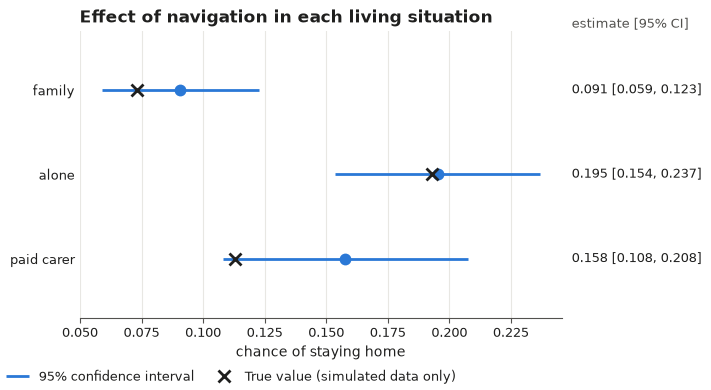

In [6]:
from cleverly import plotting

learners = {
    "outcome_learner": LogisticRegression(max_iter=1000),
    "treatment_learner": LogisticRegression(max_iter=1000),
}
# For your own data, swap in your own learners.
fit = effect.estimate(outcome_by_arm=True, random_state=0, **learners)
coefficients = fit.to_frame()[["estimand", "psi", "ci_lower", "ci_upper", "support"]]
print(coefficients.round(3).to_string(index=False))
print()
test = fit.heterogeneity_test()
print(f"test that every group has the same effect: chi-square {test.statistic:.1f} on {test.df}")
print(f"terms, p = {test.p_value:.4f}")
print()
# Each group's own effect, with a 95% interval for that group and a band that holds for all
# three groups at once.
groups = list(HOME_SUPPORT_LEVELS)
group_curve = fit.effect_curve(grid={"home_support": groups}, random_state=0)
at_groups = group_curve.predict({"home_support": groups}, interval=True)
by_group_table = pd.DataFrame(
    {
        "group": groups,
        "effect": at_groups["estimate"],
        "95% low": at_groups["ci_lower"],
        "95% high": at_groups["ci_upper"],
        "band low": group_curve.band.lower,
        "band high": group_curve.band.upper,
        "true effect": [truth[f"group_effect[{level}]"] for level in groups],  # simulation only
    }
)
print(by_group_table.round(3).to_string(index=False))
print("band label:", group_curve.band.support.label)
# The same effects drawn with their intervals: a fit without a reference group, whose three
# coefficients are the group effects themselves.
per_group = study.identify(
    ConditionalContrast(by_group, model=Indicators("home_support", intercept=False))
).estimate(outcome_by_arm=True, random_state=0, **learners)
group_fig = plotting.forest(
    {level: per_group[f"cate_projection[home_support[{level}]]"] for level in groups},
    title="Effect of navigation in each living situation",
    outcome_label="chance of staying home",
    legend="bottom",
    truth={level: truth[f"group_effect[{level}]"] for level in groups},  # simulation only
)

In the first table the intercept is family's effect, 0.091 (0.059 to 0.123). Each other row is a
difference from family: living alone gains 0.105 more (0.052 to 0.157), and a paid carer 0.067
more (0.008 to 0.126). Every row reads `supported`, meaning a simulation study checked these
intervals on fits of this kind (see How we know the method works under Go deeper). The test asks
whether every group gains the same, and p = 0.0003 says the data rule that out. A large p-value
would have said only that the data could not tell the groups apart.

The second table adds the differences back to give each group's own effect. Use the band, which
holds for all three groups at once, when you compare groups side by side; the 95% interval holds
for one group at a time. In this sample every interval and the band contain the true effect, and
the paid-carer estimate is the furthest off, 0.158 against a true 0.113. The figure draws the same three effects
with their true values.

## Does the effect change with age?

Adding a straight line in age to the groups (`Additive(Indicators(...), Linear(["age"]))`) asks
how the effect changes with age inside each group, with the same slope in every group. The
intercept is then the effect at age 0, outside the data, so the page reads the curve at ages 60,
75 and 90 instead.

change in the effect per 10 years of age: 0.045 (95% interval 0.024 to 0.065), supported
alone minus family, at the same age: 0.104 (95% interval 0.052 to 0.157)
paid carer minus family, at the same age: 0.067 (95% interval 0.008 to 0.126)
test that the effect is the same for everyone: p = 1.5e-07

home_support  age  effect  95% low  95% high  band low  band high  true effect
      family 60.0   0.046    0.009     0.084    -0.004      0.097        0.043
      family 75.0   0.113    0.080     0.147     0.068      0.158        0.088
      family 90.0   0.180    0.129     0.231     0.111      0.248        0.133
       alone 60.0   0.150    0.105     0.196     0.090      0.211        0.163
       alone 75.0   0.217    0.174     0.260     0.159      0.275        0.208
       alone 90.0   0.284    0.225     0.343     0.205      0.363        0.253
  paid carer 60.0   0.113    0.058     0.168     0.039      0.187        0.083
  paid carer 75.0   0.180    0.130     0.230     0.113      0.247   

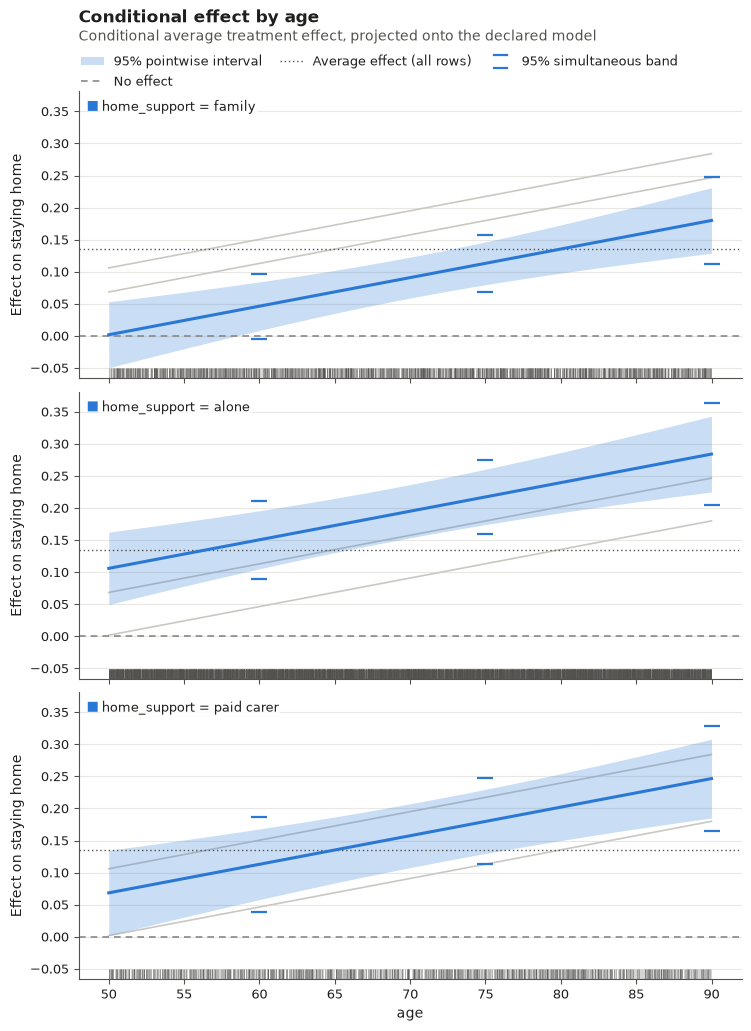

In [7]:
from cleverly.bases import Additive, Linear
from cleverly.datasets import home_support_effect

by_group_age = Modifiers(
    ["home_support", "age"],
    levels={"home_support": HOME_SUPPORT_LEVELS},
    domains={"age": (50, 90)},  # the ages the line covers; use your own range
)
shape = Additive(Indicators("home_support"), Linear(["age"]))
with_age = study.identify(ConditionalContrast(by_group_age, model=shape)).estimate(
    outcome_by_arm=True, random_state=0, **learners
)
rows = with_age.to_frame().set_index("estimand")
slope = rows.loc["cate_projection[age]"]
print(
    f"change in the effect per 10 years of age: {10 * slope['psi']:.3f} "
    f"(95% interval {10 * slope['ci_lower']:.3f} to {10 * slope['ci_upper']:.3f}), "
    f"{slope['support']}"
)
for level in ("alone", "paid carer"):
    term = rows.loc[f"cate_projection[home_support[{level}]]"]
    print(
        f"{level} minus family, at the same age: {term['psi']:.3f} "
        f"(95% interval {term['ci_lower']:.3f} to {term['ci_upper']:.3f})"
    )
age_test = with_age.heterogeneity_test()
print(f"test that the effect is the same for everyone: p = {age_test.p_value:.1e}")
print()
grid = {
    "home_support": [level for level in groups for _ in (60, 75, 90)],
    "age": [age for _ in groups for age in (60.0, 75.0, 90.0)],
}
age_curve = with_age.effect_curve(grid=grid, random_state=0)
at_ages = age_curve.predict(grid, interval=True)
print(
    pd.DataFrame(
        {
            **grid,
            "effect": at_ages["estimate"],
            "95% low": at_ages["ci_lower"],
            "95% high": at_ages["ci_upper"],
            "band low": age_curve.band.lower,
            "band high": age_curve.band.upper,
            "true effect": home_support_effect(grid["home_support"], grid["age"]),  # simulation
        }
    )
    .round(3)
    .to_string(index=False)
)
print("band label:", age_curve.band.support.label)
print(f"true change per 10 years (simulation only): {10 * truth['age_slope']:.3f}")
age_fig = age_curve.plot(
    modifier="age",
    by="home_support",
    outcome_label="staying home",
    treatment_label="navigation",
)

The effect rises by 0.045 per 10 years of age (0.024 to 0.065), against a true 0.030; in this
sample the interval excludes zero. The group differences barely move once age is in the shape
(0.104 and 0.067). The straight line is the
closest line to the true effect; here the true effect is a straight line, so the two agree. Two of
the nine 95% intervals miss the true value, both for paid carer, at 75 and 90. The band contains
all nine, and it is built to hold at all nine points together. In the simulation run for this
page (Go deeper), at least one of the nine intervals missed on 21 of 100 draws, the band on 2.

## Check the fit

predicted chance of an offer: 0.12 to 0.92
middle 98% of patients:       0.17 to 0.88
correction's equations solved: yes


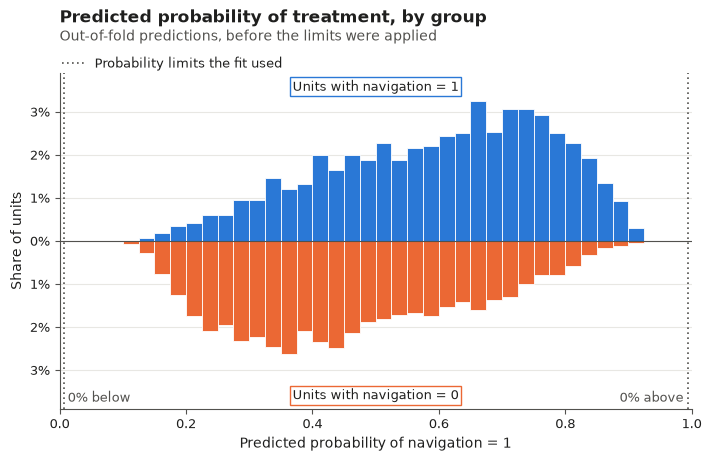

In [8]:
# The overlap check: the treatment model's predicted chance of an offer.
support = fit.diagnostics.support()
chances = support.propensity_quantiles["overall"]
print(f"predicted chance of an offer: {chances[0.0]:.2f} to {chances[1.0]:.2f}")
print(f"middle 98% of patients:       {chances[0.01]:.2f} to {chances[0.99]:.2f}")
overlap_fig = plotting.overlap(fit)
# The correction's equations: each should be solved to machine precision after the fit.
solved = fit.diagnostics.score_equations().to_frame()["passed"].all()
print("correction's equations solved:", "yes" if solved else "no")

The logistic treatment model gives every patient a chance of the offer between 0.12 and 0.92
(0.17 to 0.88 for the middle 98%). So every kind of patient appears with and without the offer,
and no weight is extreme. That range describes this treatment model; it cannot show a kind of patient
the model smooths over. The correction solved its equations.

The checks that refit the group curve on held-out rows (`curve.diagnostics`) also run here. The
page does not show them, because no simulation study has measured them for a fit like this, so
`cleverly` marks them experimental ([status and evidence](../technical-reference/conditional-effects.md#status-and-evidence)).

## What if a confounder is missing?

The omitted-variable bound asks how strong a left-out common cause of the offer and staying home
would have to be to erase a coefficient. Its strength has two sides. One is the share of the outcome's
variation that the adjusted columns leave unexplained; the other is the share of the variation in
the weights the fit uses (one over the chance of the offer, or of no offer). No simulation study has
checked the bound's limits for a coefficient, so read them as descriptive.

In [9]:
# How strong a left-out common cause of the offer and staying home would have to be to erase a
# coefficient. A strength is a share: of the outcome's variation the adjusted columns leave
# unexplained, and of the variation in the weights the fit uses.
for name, label in (
    ("cate_projection[home_support[alone]]", "alone minus family"),
    ("cate_projection[(intercept)]", "family's effect"),
):
    value = fit.sensitivity.robustness_value(estimand=name)
    bounds = fit.sensitivity.omitted_confounding(estimand=name, cf_y=0.03, cf_d=0.03)
    print(
        f"{label}: strength that erases it {value['rv']:.3f} (95% limit {value['rva']:.3f}); "
        f"range for strength 0.03 on each side {bounds.lower:.3f} to {bounds.upper:.3f}"
    )

alone minus family: strength that erases it 0.045 (95% limit 0.026); range for strength 0.03 on each side 0.036 to 0.174
family's effect: strength that erases it 0.084 (95% limit 0.059); range for strength 0.03 on each side 0.059 to 0.122


A left-out cause weaker than 0.045 on both sides cannot erase the extra gain for living alone
(0.026 with sampling error), and one weaker than 0.084 cannot erase family's own effect. Read each
value as a floor: a cause stronger on one side can erase the effect with the other side below it.
At strength 0.03 on each side the difference moves to between 0.036 and 0.174 before sampling
error, so it stays above zero. Whether a cause that strong is plausible is a judgment about how the
teams chose. Two other checks of a missing confounder, the E-value and a simulated-confounder
test, do not run on a coefficient of this fit
([refusals](../technical-reference/conditional-effects.md#refusals)).

## What we can and can't conclude

For the program manager: navigation helps patients in every living situation, and those who live
alone gain most. The offer raised their chance of staying home for 30 days by about 0.195 against
0.091 for patients with family, a difference of 0.105 with a 95% interval of 0.052 to 0.157. In
this sample the effect also grows with age, by about 0.045 per 10 years.

All of it rests on age, discharge risk and living situation accounting for how the teams chose
who got the offer, and no check on this page can confirm that. The checks under Go deeper found
nothing wrong: with the offer column shuffled the difference falls to near zero, and an added
noise column and random subsets leave it in place. A left-out cause weaker than 0.045 on both
sides cannot erase the difference. To target navigation at patients who live alone with more
confidence, offer it at random within each group for a period, which needs none of these
conditions.

The page shows one simulated draw. It does not show that the groups differ by this much in your
data, or how the method performs in general; the simulation studies under Go deeper speak to
that.

## Go deeper

### Try to break the result

Each check refits the alone-minus-family difference on changed data.

In [10]:
# Three checks that refit the "alone minus family" difference: the offer column shuffled (the
# difference should vanish), an added column of noise, and random subsets (both should leave it
# about where it was).
refutation = fit.diagnostics.refute(estimand="cate_projection[home_support[alone]]", random_state=0)
columns = ["test", "original", "refuted_mean", "refuted_sd", "verdict"]
print(refutation.to_frame()[columns].round(3).to_string(index=False))

               test  original  refuted_mean  refuted_sd     verdict
            placebo     0.105        -0.004       0.023 descriptive
random_common_cause     0.105         0.105       0.000 descriptive
             subset     0.105         0.107       0.016 descriptive


With the offer column shuffled, the difference falls from 0.105 to -0.004, as a real effect
should. An added column of noise leaves it at 0.105, and random subsets give 0.107, about where it
was. Each line reads `descriptive`: `cleverly` gives a pass or fail only when a simulation study
backs that check for this kind of fit. Here none does, so it shows the numbers and you judge
them.

### How we know the method works

Simulation studies check each fit on the page over many repeated samples:

| section | fit | study | data |
| --- | --- | --- | --- |
| Estimate the effect in each group; Does the effect change with age? | projection coefficients, band and test | [conditional-projection](../technical-reference/method-evidence/conditional-projection.md) (coefficients, test); [projection-evidence](../technical-reference/method-evidence/projection-evidence.md) (band) | other data |
| What if a confounder is missing? | bound on a coefficient | none: [ovb-limit-coverage](../technical-reference/method-evidence/ovb-limit-coverage.md) covers an average effect only | none |
| Try to break the result | `refute` | nearest: [refuter calibration](../technical-reference/method-evidence/refuter-calibration-point.md) | other data |
| Does navigation help beyond the 7-day visit? | direct-effect projection | [projection-evidence](../technical-reference/method-evidence/projection-evidence.md) | other data |
| Does the age trend differ between groups? | `strata=` | [projection-compositions](../technical-reference/method-evidence/projection-compositions.md) | other data |
| The same groups as risk ratios | log-ratio projection | [conditional-projection](../technical-reference/method-evidence/conditional-projection.md) | other data |

The studies fit a straight line in two continuous columns, with a flexible outcome model in each
arm. No study fits group indicators as the shape, a logistic outcome model that cannot match the
simulation, or a band of a direct effect, so for those parts the label rests on the method's theory. A
simulation run for this page, 100 draws of these data with every fit above
(`reviews/notebook-review/probes/subgroup-effects/`), checks the page's readings, not the method.
The [conditional effects reference](../technical-reference/conditional-effects.md#status-and-evidence)
states what each study measures.

### Does navigation help beyond the 7-day visit?

The offer also makes a primary-care visit within 7 days more likely, and the visit itself helps
patients stay home. The controlled direct effect asks what the offer does with every patient's
visit held at one level, here no visit and a visit (`ControlledDirectEffect`). It needs two more
conditions. No unrecorded common cause of the visit and staying home may remain once the offer
and the adjusted columns are known, which the data cannot check. And every arm and group must
hold patients with and without a visit. A model of the visit (`intermediate_learner`) joins the other two.

In [11]:
from cleverly import ControlledDirectEffect

# A design that names the visit (intermediate=) is its own study.
held_study = CausalStudy(
    frame, design=replace(design, intermediate="pcp_visit_7d"), protocol=protocol
)
direct_rows = []
for visit in (0, 1):
    direct = held_study.identify(
        ControlledDirectEffect(
            intermediate=float(visit),
            contrast=ConditionalContrast(by_group, model=Indicators("home_support")),
        )
    ).estimate(
        outcome_by_arm=True,
        random_state=0,
        intermediate_learner=LogisticRegression(max_iter=1000),  # predicts the visit
        **learners,
    )
    direct_curve = direct.effect_curve(grid={"home_support": groups}, random_state=0)
    at_visit = direct_curve.predict({"home_support": groups}, interval=True)
    for j, level in enumerate(groups):
        direct_rows.append(
            {
                "visit held at": "yes" if visit else "no",
                "group": level,
                "effect": at_visit["estimate"].iloc[j],
                "95% low": at_visit["ci_lower"].iloc[j],
                "95% high": at_visit["ci_upper"].iloc[j],
                "true effect": truth[f"direct_effect[visit={visit}][{level}]"],  # simulation
            }
        )
    labels = direct.to_frame()["support"]
    print(f"visit held at {'yes' if visit else 'no'}: coefficients {set(labels)}, band", end=" ")
    print(direct_curve.band.support.label)
print(pd.DataFrame(direct_rows).round(3).to_string(index=False))
# simulation only: the true total effect minus the true direct effect, the same in every group
for visit in (0, 1):
    gaps = {
        level: truth[f"group_effect[{level}]"] - truth[f"direct_effect[visit={visit}][{level}]"]
        for level in groups
    }
    print(f"true total minus direct, visit held at {'yes' if visit else 'no'}:", end=" ")
    print({level: round(gap, 3) for level, gap in gaps.items()})

visit held at no: coefficients {'supported'}, band experimental


visit held at yes: coefficients {'supported'}, band experimental
visit held at      group  effect  95% low  95% high  true effect
           no     family   0.016   -0.029     0.061         0.02
           no      alone   0.158    0.102     0.214         0.14
           no paid carer   0.086    0.013     0.158         0.06
          yes     family   0.122    0.070     0.175         0.06
          yes      alone   0.168    0.096     0.240         0.18
          yes paid carer   0.187    0.112     0.262         0.10
true total minus direct, visit held at no: {'family': 0.053, 'alone': 0.053, 'paid carer': 0.053}
true total minus direct, visit held at yes: {'family': 0.013, 'alone': 0.013, 'paid carer': 0.013}


With the visit held at no, the direct effects are 0.016, 0.158 and 0.086 against true values of
0.02, 0.14 and 0.06, and living alone still gains most. In the simulation the total effect exceeds
the direct effect with the visit held at no by the same 0.053 in every group, and by 0.013 with it
held at yes. So the differences between groups are the same for the total effect and both direct
effects: they do not run through the visit.

With the visit held at yes the intervals are wider, and two miss: family, 0.122 against a true
0.06, and paid carer, 0.187 against 0.10. Over the 100 simulated draws each coefficient's interval
at this level covered its true value on 0.95 to 0.96 of them, so these misses are sampling
variation on a draw that runs high. All three intervals covered together on 84 of the 100 draws,
near what three separate 95% intervals give. With the visit held at no, the family coefficient's
interval covered its true value on every draw, so that interval may be wider than it needs to be.

The coefficients read `supported`. The band reads experimental, because no study has measured a
band of a direct effect. The held-out curve checks and the score checks refuse on a direct effect
([refusals](../technical-reference/conditional-effects.md#refusals)).

### Does the age trend differ between groups?

`strata=` fits the line in age separately inside each living situation, so each group gets its
own slope rather than the shared slope of the main path.

In [12]:
# strata= fits the same straight line in age separately inside each group.
by_age = Modifiers(["age"], domains={"age": (50, 90)})
strata_fit = (
    CausalStudy(frame, design=replace(design, strata=("home_support",)), protocol=protocol)
    .identify(ConditionalContrast(by_age, model=Linear(["age"])))
    .estimate(outcome_by_arm=True, random_state=0, **learners)
)
inside = strata_fit.to_frame()
inside = inside[inside["estimand"].str.contains("home_support=")]
print(
    inside[["estimand", "psi", "ci_lower", "ci_upper", "support"]].round(4).to_string(index=False)
)
print("true slope in every group:", truth["age_slope"])

                                               estimand     psi  ci_lower  ci_upper   support
    cate_projection[(intercept)][home_support='family'] -0.1794   -0.3822    0.0234 supported
            cate_projection[age][home_support='family']  0.0039    0.0010    0.0067 supported
cate_projection[(intercept)][home_support='paid carer'] -0.1525   -0.4692    0.1641 supported
        cate_projection[age][home_support='paid carer']  0.0044    0.0001    0.0088 supported
     cate_projection[(intercept)][home_support='alone'] -0.1906   -0.4503    0.0691 supported
             cate_projection[age][home_support='alone']  0.0055    0.0018    0.0092 supported
true slope in every group: 0.003


The slopes per year of age are 0.0039 for family, 0.0055 for living alone and 0.0044 for a paid
carer, and each interval contains the true 0.003. Each group's line uses only that group's
patients, so its interval is wider than the shared slope's on the main path, and the three
intervals overlap widely. The intercepts are effects at age 0 and are not read. Each row reads
`supported`.

### The same groups as risk ratios

On the ratio scale (`scale="log_ratio"`) the question is how many times more likely staying home
is with the offer than without it, in each group.

In [13]:
ratio_fit = study.identify(
    ConditionalContrast(by_group, scale="log_ratio", model=Indicators("home_support"))
).estimate(outcome_by_arm=True, random_state=0, **learners)
print("label:", set(ratio_fit.to_frame()["support"]))
ratio_curve = ratio_fit.effect_curve(grid={"home_support": groups}, random_state=0)
on_log = ratio_curve.predict({"home_support": groups}, interval=True)
print(
    pd.DataFrame(
        {
            "group": groups,
            "risk ratio": np.exp(on_log["estimate"]),
            "95% low": np.exp(on_log["ci_lower"]),
            "95% high": np.exp(on_log["ci_upper"]),
            "true ratio": [truth[f"risk_ratio[{level}]"] for level in groups],  # simulation
            "true rate without offer": [truth[f"untreated_rate[{level}]"] for level in groups],
        }
    )
    .round(3)
    .to_string(index=False)
)
ratio_test = ratio_fit.heterogeneity_test()
print(f"test that every group has the same ratio: p = {ratio_test.p_value:.4f}")

label: {'supported'}
     group  risk ratio  95% low  95% high  true ratio  true rate without offer
    family       1.251    1.155     1.354       1.193                    0.377
     alone       1.654    1.467     1.864       1.649                    0.298
paid carer       1.451    1.290     1.633       1.299                    0.377
test that every group has the same ratio: p = 0.0005


The risk ratios are 1.251 for family, 1.654 for living alone and 1.451 for a paid carer, against
true values of 1.193, 1.649 and 1.299; every interval contains its true value. Without the offer,
patients who live alone have the lowest chance of staying home (a true 0.298 against 0.377), so
the same gain in points is a larger ratio for them. Whether groups "differ" depends on the scale:
equal differences in points mean unequal ratios when the starting chances differ. The test that
every group has the same ratio gives p = 0.0005. The fit reads `supported`. No omitted-variable
bound runs on a ratio coefficient, and the refutation checks do
([refusals](../technical-reference/conditional-effects.md#refusals)).

## Where to go next

[Who gains most from a coupon](conditional-effects.ipynb) fits an effect that changes along a
continuous characteristic, ranks customers by it, and checks a score on held-out rows. [Gain over
current practice](population-impact.ipynb) fits the direct effect for the whole population. The
[conditional effects guide](../user-guide/conditional-effects.md) covers the shapes, their
intervals and the other settings, and the
[conditional effects reference](../technical-reference/conditional-effects.md) states the exact
quantities and conditions. The [examples index](index.md) lists every example.